# Momentum integrators and higher-order overdamped dynamics
Kinetic Euler evolves $(x,p)$ with $dx=p\,dt$, $dp=-\nabla U\,dt-\gamma p\,dt+\sqrt{2\gamma}dW$. BAOAB splits force, position and exact Ornstein–Uhlenbeck steps. HOLA is a higher-order **overdamped** scheme, with Hessian actions and gradient of the Laplacian; it is not a momentum integrator. [R05](../docs/references.md#r05), [R06](../docs/references.md#r06), [R07](../docs/references.md#r07).

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


In [2]:
from lafa.specialized import HOLA
# Exact derivative provider avoids repeated dense autograd for a Gaussian.
class GaussianDerivatives:
    def gradient(self,x): return x
    def hvp(self,x,v): return v
    def spectral_norm(self,x): return x.new_tensor(1.)
    def grad_laplacian(self,x): return torch.zeros_like(x)
target=Gaussian([0,0],[[1,0],[0,1]],device=device,dtype=dtype)
steps=700 if quick else 2400; burn=250 if quick else 800
x=torch.zeros((32,2),device=device,dtype=dtype)
methods={'Kinetic Euler':samplers.KineticLangevin(target,x,.15,generator=gen(1)),
         'BAOAB':samplers.BAOAB(target,x,.15,generator=gen(2)),
         'HOLA tamed':HOLA(target,x,.15,derivatives=GaussianDerivatives(),generator=gen(3)),
         'HOLA untamed':HOLA(target,x,.15,tamed=False,derivatives=GaussianDerivatives(),generator=gen(4))}
results={}; rows=[]; momentum={}
for name,m in methods.items():
    ps=[]; samples=[]; trace=[]; sync(); start=time.perf_counter()
    for i in range(steps):
        r=m.step(); trace.append(r.position[0].clone())
        if hasattr(m,'momentum'): ps.append(m.momentum[0].clone())
        if i>=burn: samples.append(r.position)
    sync(); seconds=time.perf_counter()-start
    s=torch.cat(samples); results[name]=(s,torch.stack(trace)); momentum[name]=torch.stack(ps) if ps else None
    rows.append(dict(method=name,seconds=seconds,covariance_error=float((covariance(s)-target.covariance).norm()),momentum_variance=float(torch.stack(ps)[burn:,0].var()) if ps else 'not applicable'))
table(rows)

| method | seconds | covariance_error | momentum_variance |
|---|---|---|---|
| Kinetic Euler | 0.2197 | 0.2376 | 1.11 |
| BAOAB | 0.2347 | 0.08009 | 1.113 |
| HOLA tamed | 2.888 | 0.1606 | not applicable |
| HOLA untamed | 1.794 | 0.0491 | not applicable |

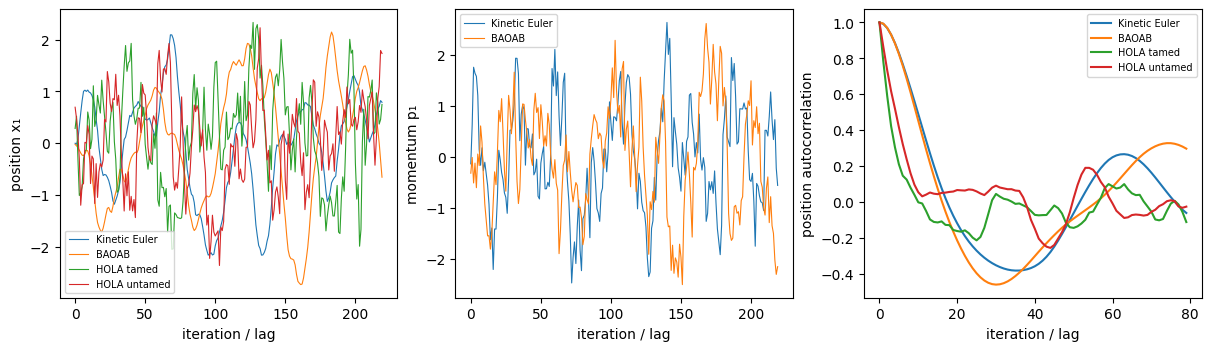

In [3]:
def acf(z,maxlag=80):
    z=z-z.mean(); return torch.stack([(z[:len(z)-k]*z[k:]).mean()/z.square().mean() for k in range(maxlag)])
fig,ax=plt.subplots(1,3,figsize=(12,3.4),layout='constrained')
for name,(s,tr) in results.items():
    ax[0].plot(cpu(tr[:220,0]),label=name,lw=.8)
    ax[2].plot(cpu(acf(tr[burn:,0])),label=name)
for name in ['Kinetic Euler','BAOAB']: ax[1].plot(cpu(momentum[name][:220,0]),label=name,lw=.8)
for a,y in zip(ax,['position x₁','momentum p₁','position autocorrelation']): a.set(xlabel='iteration / lag',ylabel=y); a.legend(fontsize=7)
plt.show()

The autocorrelation uses one short stationary segment, so it is descriptive. Equal iteration counts are unequal derivative work: Euler and BAOAB use one new gradient per step; HOLA additionally needs exact Hessian actions, a spectral norm and third derivatives. The provider above supplies those analytically.

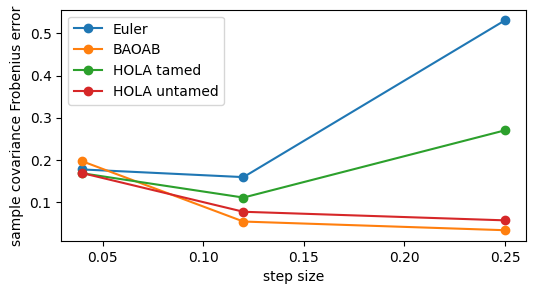

| method | step | covariance_error |
|---|---|---|
| Euler | 0.04 | 0.1771 |
| BAOAB | 0.04 | 0.1964 |
| HOLA tamed | 0.04 | 0.168 |
| HOLA untamed | 0.04 | 0.1683 |
| Euler | 0.12 | 0.1589 |
| BAOAB | 0.12 | 0.05342 |
| HOLA tamed | 0.12 | 0.1104 |
| HOLA untamed | 0.12 | 0.07665 |
| Euler | 0.25 | 0.5315 |
| BAOAB | 0.25 | 0.03283 |
| HOLA tamed | 0.25 | 0.2701 |
| HOLA untamed | 0.25 | 0.05625 |

In [4]:
rows=[]
for h in [.04,.12,.25]:
    for name,cls,kw in [('Euler',samplers.KineticLangevin,{}),('BAOAB',samplers.BAOAB,{}),('HOLA tamed',HOLA,{'derivatives':GaussianDerivatives()}),('HOLA untamed',HOLA,{'tamed':False,'derivatives':GaussianDerivatives()})]:
        s,_,_,_=collect(cls(target,x,h,generator=gen(12),**kw),steps,burn,2)
        rows.append(dict(method=name,step=h,covariance_error=float((covariance(s)-target.covariance).norm())))
fig,ax=plt.subplots(figsize=(6,3))
for name in dict.fromkeys(r['method'] for r in rows):
    rr=[r for r in rows if r['method']==name]; ax.plot([r['step'] for r in rr],[r['covariance_error'] for r in rr],'o-',label=name)
ax.set(xlabel='step size',ylabel='sample covariance Frobenius error'); ax.legend(); plt.show(); table(rows)

In [5]:
# Exercise the small-dimensional dense reference on a genuinely nonlinear target.
quartic=lambda z: z.pow(4).sum(-1)/4+z.square().sum(-1)/2
dense=HOLA(quartic,tensor([.3,-.2]),.02,max_dense_dimension=8,generator=gen(50))
for _ in range(4): dense.step()
print('Dense nonlinear HOLA result:',dense.position)
try:
    HOLA(quartic,torch.zeros(9,device=device,dtype=dtype),.02,max_dense_dimension=8)
except ValueError as error: print('Expected resource guard:',error)

Dense nonlinear HOLA result: tensor([ 0.8251, -0.3834], dtype=torch.float64)
Expected resource guard: dense HOLA dimension guard; supply exact derivative provider


Untamed HOLA is appropriate here because the Gaussian has globally Lipschitz derivatives. The quartic example uses taming. The finite-run sweep includes Monte Carlo error and different mixing times; it is not an estimate of asymptotic convergence order. Dense HOLA is guarded because Hessian storage grows quadratically.